# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import MAR20Dataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 3842


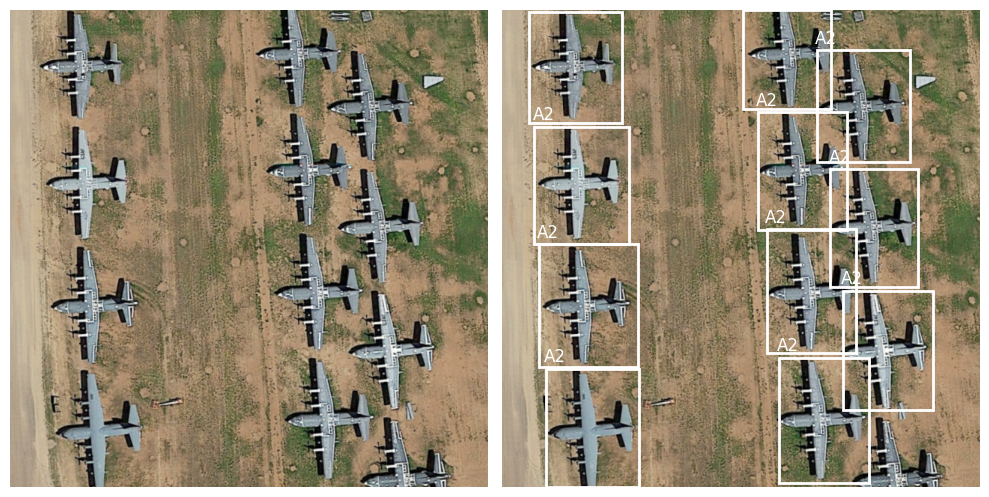

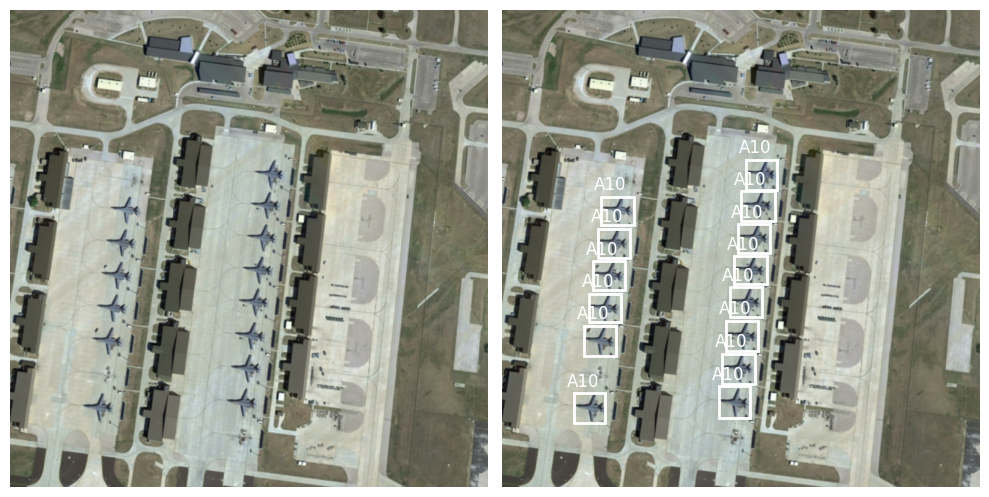

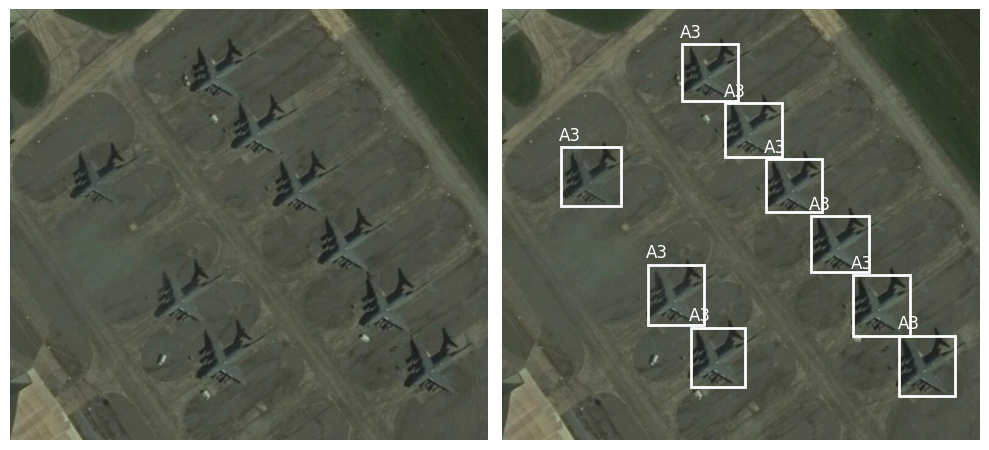

In [ ]:
dataset_config = {
    "image_dir": "./data/MAR20/JPEGImages/",
    "annotations_dir": "./data/MAR20/Annotations/Horizontal Bounding Boxes/",
}
dataset = MAR20Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1);
dataset.show_image(30);
dataset.show_image(90);

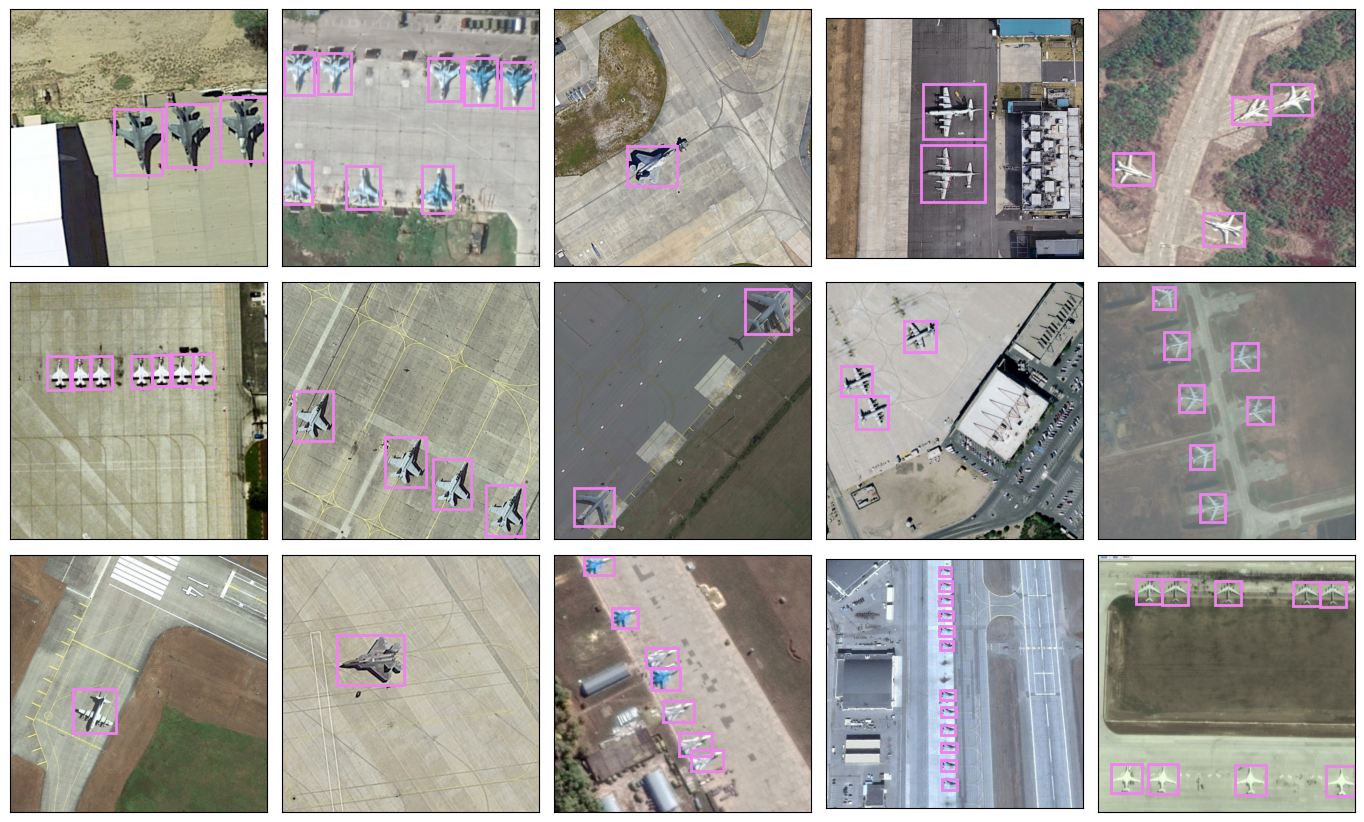

In [11]:
dataset.show_batch(15);

In [12]:
dataset.data_distribution_table()

,Label,Count
0,A9,1086
1,A8,944
2,A7,680
3,A6,441
4,A5,1262
5,A4,642
6,A3,1176
7,A20,981
8,A2,1729
9,A19,1236


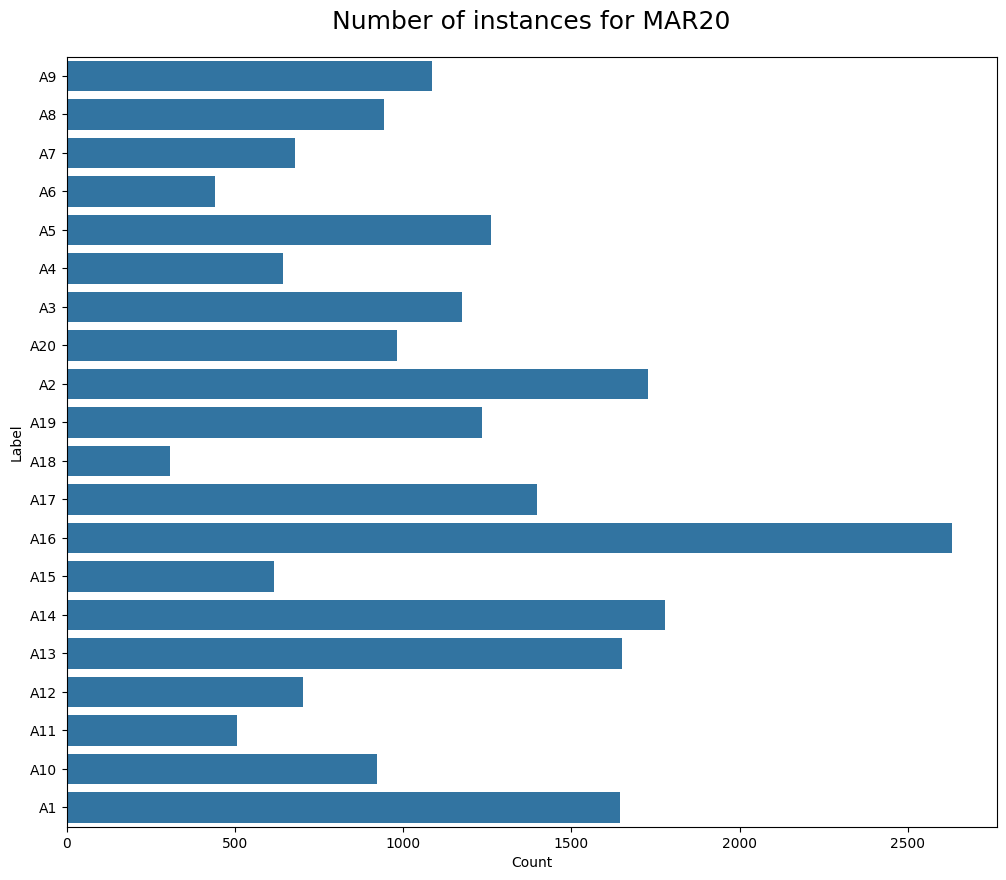

In [13]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "image_dir": "./data/MAR20/JPEGImages/",
    "annotations_dir": "./data/MAR20/Annotations/Horizontal Bounding Boxes/",
    "csv_file": "./data/MAR20/ImageSets/Main/train.txt",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = MAR20Dataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 1331


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/MAR20/experiments/"
model_config = {
    "num_classes": 21,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [11]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-28 10:33:55,086 INFO Starting training.
training: 100%|██████████| 167/167 [00:54<00:00,  3.05it/s]
2025-05-28 10:34:49,827 INFO epoch: 1, time: 54, loss:  0.89043
testing on train set: 100%|██████████| 167/167 [00:29<00:00,  5.61it/s]
2025-05-28 10:35:23,705 INFO map:0.18783850967884064, map_50:0.29523321986198425, map_75:0.2263822853565216, map_small:0.1657293140888214, map_medium:0.1884188950061798, map_large:0.16271065175533295, mar_1:0.06153261289000511, mar_10:0.23228278756141663, mar_100:0.2455766201019287, mar_small:0.25742197036743164, mar_medium:0.24594692885875702, mar_large:0.18945904076099396, map_per_class:tensor(0.2295), tensor(0.1903), tensor(0.), tensor(0.0092), tensor(0.4164), tensor(0.4089), tensor(0.), tensor(0.4449), tensor(0.5857), tensor(0.), tensor(0.4350), tensor(0.0072), tensor(0.5733), tensor(0.), tensor(0.), tensor(0.4360), tensor(0.), tensor(0.), tensor(0.0035), tensor(0.0168), mar_100_per_class:tensor(0.3188), tensor(0.2024), tensor(0.), tensor(0.0

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "image_dir": "./data/MAR20/JPEGImages/",
    "annotations_dir": "./data/MAR20/Annotations/Horizontal Bounding Boxes/",
    "csv_file": "./data/MAR20/ImageSets/Main/test.txt",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = MAR20Dataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/MAR20/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 2511


2025-05-28 10:49:31,502 INFO Loading checkpoint /home/dragik/data/FAIR_EO/MAR20/experiments/checkpoint.pth.tar
2025-05-28 10:49:31,907 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/MAR20/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 314/314 [01:04<00:00,  4.88it/s]


[{'map': 0.4255622327327728,
  'map_50': 0.599437415599823,
  'map_75': 0.5416998863220215,
  'map_small': 0.21573132276535034,
  'map_medium': 0.4471672475337982,
  'map_large': 0.35211989283561707,
  'mar_1': 0.14932391047477722,
  'mar_10': 0.506157636642456,
  'mar_100': 0.5148940682411194,
  'mar_small': 0.25470805168151855,
  'mar_medium': 0.533726155757904,
  'mar_large': 0.433125764131546,
  'map_per_class': [tensor(0.5017),
   tensor(0.6591),
   tensor(0.2910),
   tensor(0.4983),
   tensor(0.1852),
   tensor(0.4030),
   tensor(0.2182),
   tensor(0.3643),
   tensor(0.6042),
   tensor(0.3209),
   tensor(0.4293),
   tensor(0.2746),
   tensor(0.4863),
   tensor(0.5339),
   tensor(0.2424),
   tensor(0.2977),
   tensor(0.6379),
   tensor(0.6222),
   tensor(0.5550),
   tensor(0.3859)],
  'mar_100_per_class': [tensor(0.6186),
   tensor(0.7174),
   tensor(0.3862),
   tensor(0.5946),
   tensor(0.2021),
   tensor(0.5275),
   tensor(0.5376),
   tensor(0.4186),
   tensor(0.6719),
   tensor

## Predictions

2025-05-28 10:54:04,723 INFO Loading checkpoint /home/dragik/data/FAIR_EO/MAR20/experiments/checkpoint.pth.tar
2025-05-28 10:54:04,992 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/MAR20/experiments/checkpoint.pth.tar at epoch 11


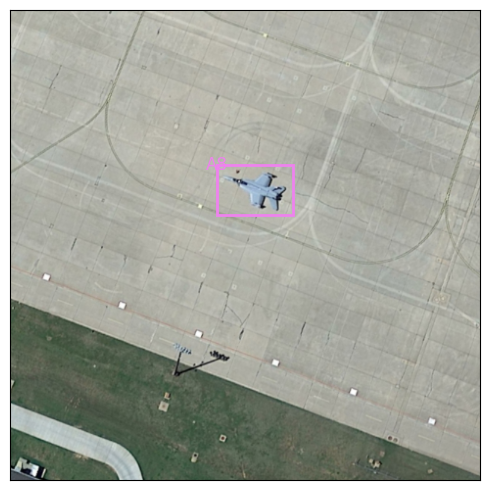

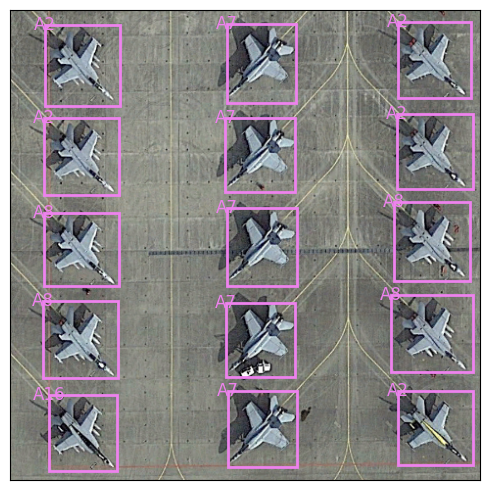

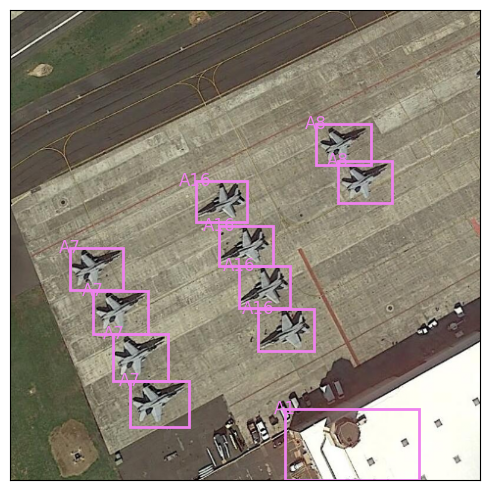

In [ ]:
model_config = {
    "num_classes": 21,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/MAR20/experiments/checkpoint.pth.tar"
labels = ['no-data','A1','A2','A3','A4','A5','A6','A7','A8','A9','A10','A11','A12','A13','A14','A15','A16','A17','A18','A19','A20']
transform = Resize()
model.load_model(model_path)

csv_file = "./data/MAR20/ImageSets/Main/test.txt"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = file.readlines()
    for lines in csvFile:
        test_list.append(lines[: -1])

image = image_loader('./data/MAR20/JPEGImages/' + test_list[0] + '.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/MAR20/JPEGImages/' + test_list[5] + '.jpg')
image = image[:,:,0:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/MAR20/JPEGImages/' + test_list[10] + '.jpg')
fig = model.detect_objects(image, labels, transform)